In [1]:
import sys
sys.path.append("..")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_dataset, split_data
from src.models import *
from src.evaluate import *
from src.explain import oof_shap
from src.segment import *
from sklearn.metrics import adjusted_rand_score

telco
 k  inertia  silhouette  stability_ARI
 2 5195.416       0.398          1.000
 3 4459.721       0.262          0.984
 4 3801.697       0.235          0.997
 5 3385.935       0.233          0.988
 6 2978.605       0.242          0.998
 7 2779.193       0.232          0.971
 8 2583.462       0.231          0.917



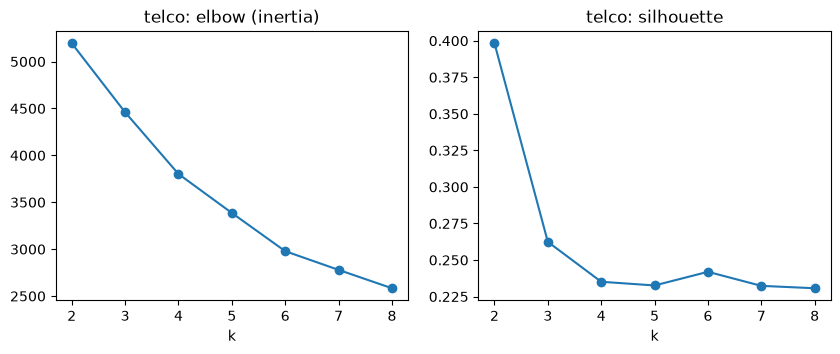

bank
 k   inertia  silhouette  stability_ARI
 2 13745.937       0.357          1.000
 3  9852.556       0.341          0.999
 4  7549.751       0.360          1.000
 5  6523.616       0.360          1.000
 6  6006.209       0.345          0.978
 7  5570.267       0.295          0.997
 8  5265.481       0.225          0.838



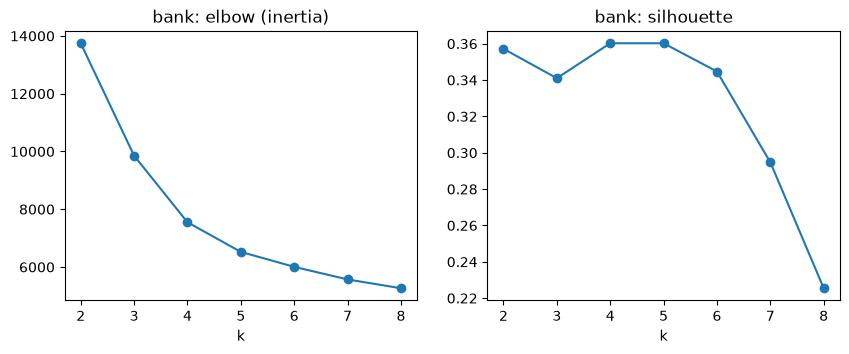

In [2]:
for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    sv = np.load(f"../results/shap_{name}.npy")
    Xt = pd.read_csv(f"../results/shap_features_{name}.csv")
    Z = aggregate_shap(sv, list(Xt.columns), list(X_train.columns))
    Z.to_csv(f"../results/shap_by_feature_{name}.csv", index=False)

    scan = k_scan(Z)
    scan.to_csv(f"../results/k_scan_{name}.csv", index=False)
    print(name); print(scan.round(3).to_string(index=False)); print()

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(scan["k"], scan["inertia"], marker="o"); ax[0].set_title(f"{name}: elbow (inertia)")
    ax[1].plot(scan["k"], scan["silhouette"], marker="o"); ax[1].set_title(f"{name}: silhouette")
    for a in ax: a.set_xlabel("k")
    plt.savefig(f"../figures/k_scan_{name}.png", bbox_inches="tight"); plt.show()

In [4]:
K = {"telco": 6, "bank": 4}   

for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    Z = pd.read_csv(f"../results/shap_by_feature_{name}.csv")
    Xt = pd.read_csv(f"../results/shap_features_{name}.csv")     # raw-feature baseline input
    y = y_train.values

    shap_seg = fit_kmeans(Z, K[name])
    raw_seg = fit_kmeans(Xt, K[name])

    for label, seg in [("SHAP-based", shap_seg), ("raw-feature", raw_seg)]:
        t = pd.DataFrame({"segment": seg, "churn": y}).groupby("segment")["churn"].agg(["size", "mean"]).round(3)
        print(name, label, "| churn-rate spread:", round(t["mean"].max() - t["mean"].min(), 3))
        print(t.to_string()); print()
    print(name, "agreement between the two groupings (ARI):", round(adjusted_rand_score(shap_seg, raw_seg), 3), "\n")

    pd.DataFrame({"shap_segment": shap_seg, "raw_segment": raw_seg, "churn": y},
                 index=X_train.index).to_csv(f"../results/segments_{name}.csv")

telco SHAP-based | churn-rate spread: 0.654
         size   mean
segment             
0         943  0.243
1        1067  0.017
2        1225  0.384
3         523  0.046
4         934  0.671
5         942  0.135

telco raw-feature | churn-rate spread: 0.498
         size   mean
segment             
0         372  0.231
1        1180  0.237
2        1193  0.070
3        1314  0.120
4        1048  0.568
5         527  0.554

telco agreement between the two groupings (ARI): 0.231 

bank SHAP-based | churn-rate spread: 0.808
         size   mean
segment             
0        1796  0.435
1        3079  0.047
2         256  0.855
3        2869  0.169

bank raw-feature | churn-rate spread: 0.191
         size   mean
segment             
0        2296  0.205
1        2007  0.152
2        1754  0.131
3        1943  0.322

bank agreement between the two groupings (ARI): 0.1 



In [5]:
KEY = {"telco": ["tenure", "MonthlyCharges", "Contract", "InternetService", "PaymentMethod"],
       "bank": ["Age", "NumOfProducts", "IsActiveMember", "Geography", "Balance", "Gender"]}

for name in ["telco", "bank"]:
    X_train, X_test, y_train, y_test = split_data(load_dataset(name))
    seg = pd.read_csv(f"../results/segments_{name}.csv", index_col=0)["shap_segment"]
    Z = pd.read_csv(f"../results/shap_by_feature_{name}.csv"); Z.index = X_train.index

    num = X_train.select_dtypes("number").columns
    cat = X_train.select_dtypes(exclude="number").columns
    prof = pd.concat([X_train[num].groupby(seg).mean().round(2),
                      X_train[cat].groupby(seg).agg(lambda s: f"{s.mode()[0]} ({(s==s.mode()[0]).mean():.0%})")], axis=1)
    prof.insert(0, "size", seg.value_counts().sort_index())
    prof.insert(1, "churn", y_train.groupby(seg).mean().round(3))
    prof.to_csv(f"../results/segment_profile_{name}.csv")

    print("=====", name, "=====")
    print(prof[["size", "churn"] + KEY[name]].sort_values("churn", ascending=False).to_string())
    ms = Z.groupby(seg).mean()
    for s in prof.sort_values("churn", ascending=False).index:
        r = ms.loc[s].sort_values()
        print(f"segment {s} (churn {prof.loc[s,'churn']}): pushes risk UP -> {list(r.index[-3:][::-1])} | DOWN -> {list(r.index[:3])}")
    print()

===== telco =====
              size  churn  tenure  MonthlyCharges               Contract    InternetService                    PaymentMethod
shap_segment                                                                                                                
4              934  0.671    4.14           73.63  Month-to-month (100%)  Fiber optic (77%)           Electronic check (64%)
2             1225  0.384   34.46           83.18  Month-to-month (100%)  Fiber optic (81%)           Electronic check (54%)
0              943  0.243   10.78           37.75  Month-to-month (100%)          DSL (55%)               Mailed check (47%)
5              942  0.135   46.94           79.99         One year (93%)  Fiber optic (50%)    Credit card (automatic) (29%)
3              523  0.046   69.33           84.44         Two year (95%)  Fiber optic (50%)  Bank transfer (automatic) (41%)
1             1067  0.017   43.40           37.52         Two year (75%)           No (67%)               M